# CCS discovery with successor features: standard SFOLS vs. Certify-or-Grow (DST)

**Goal.** Build the full Convex Coverage Set (CCS) on Deep Sea Treasure two ways, with
*every CCS policy carrying its successor features*, and measure the speedup:

| | per queried corner weight `w` | what each CCS policy stores |
|---|---|---|
| **Standard SFOLS** | exact policy iteration over the full action set | action map, $\Psi(s)$, $\Psi(s,a)$ |
| **Certify-or-Grow** | restricted policy iteration over the basis' own actions (metapolicy), Bellman-gap certificate, exact fallback solve only if the certificate fails | action map, $\Psi(s)$, $\Psi(s,a)$ |

**Why the SFs matter.** The CCS is only useful if, at an *unseen* weight, GPI over it gives
the optimal policy in one shot. That needs each CCS policy's SFs at *every* state, not just
the vertex $\psi(s_0)$. `SFOLS/03_adaptive_basis.ipynb`'s `sfols_certified` computed the
metapolicy's $\Psi(s)$ for all states but kept only $\psi(s_0)$, so its CCS couldn't be used
for transfer and its 2.27x speedup compared unequal outputs. Here both sides return the same
object.

**What's different from `03` (on purpose).**
1. *One shared OLS loop* - both methods differ only in the per-weight query function, so the
   sequence of queried weights is identical and timing differences come only from solving.
2. *Exact 2-D corner weights* (line intersections) instead of a 2000-point grid, and no
   re-querying of already-visited weights (`03`'s run queried `w=[0.47,0.53]` three times).
3. *Vectorized exact model* - transitions tabulated once as `NEXT[s,a]`, `PHI[s,a]`,
   `DONE[s,a]`; every solver (both methods) uses the same numpy primitives, so neither side is
   penalized by Python-loop overhead.

Everything is exact (tabular, known model, no Q-learning). Kernel: `okb`.

## 0. Setup

In [1]:
import heapq
import itertools
import time
from collections import defaultdict
from contextlib import contextmanager
from dataclasses import dataclass
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import mo_gymnasium as mo_gym
from scipy.optimize import linprog

np.set_printoptions(suppress=True, precision=3)

env = mo_gym.make("deep-sea-treasure-v0")
core = env.unwrapped
GAMMA = 0.99
N_ACTIONS = core.action_space.n
FEAT_DIM = 2
START_STATE = (0, 0)

ground_truth_ccs = np.array(core.pareto_front(gamma=GAMMA))
print(f"{N_ACTIONS} actions, {FEAT_DIM} objectives, ground-truth CCS: {len(ground_truth_ccs)} points")

4 actions, 2 objectives, ground-truth CCS: 10 points


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gymnasium/spaces/box.py:297: UserWarning: WARN: Box high's precision lowered by casting to float32, current high.dtype=float64
  gym.logger.warn(


## 1. Exact tabular model

DST is deterministic, so the model is three arrays over (state, action). Terminal (treasure)
states are absorbing with zero features and zero SFs.

In [2]:
def _step(s, a):
    ns = (s[0] + int(core.dir[a][0]), s[1] + int(core.dir[a][1]))
    if not (0 <= ns[0] < core.sea_map.shape[0] and 0 <= ns[1] < core.sea_map.shape[1]) \
            or core.sea_map[ns] == -10:
        ns = s
    treasure = core.sea_map[ns]
    terminal = treasure != 0 and treasure != -10
    return ns, np.array([treasure if terminal else 0.0, -1.0]), terminal


states = [(r, c) for r in range(core.sea_map.shape[0]) for c in range(core.sea_map.shape[1])
          if core.sea_map[r, c] != -10]
state_idx = {s: i for i, s in enumerate(states)}
S = len(states)
S0 = state_idx[START_STATE]
TERMINAL = np.array([core.sea_map[s] != 0 for s in states])
NONTERM = ~TERMINAL

NEXT = np.tile(np.arange(S)[:, None], (1, N_ACTIONS))   # terminal rows: self-loop
PHI = np.zeros((S, N_ACTIONS, FEAT_DIM))                # terminal rows: zero features
DONE = np.ones((S, N_ACTIONS), dtype=bool)              # terminal rows: no bootstrap
for s in states:
    if TERMINAL[state_idx[s]]:
        continue
    for a in range(N_ACTIONS):
        ns, phi, term = _step(s, a)
        NEXT[state_idx[s], a] = state_idx[ns]
        PHI[state_idx[s], a] = phi
        DONE[state_idx[s], a] = term

print(f"|S|={S} ({NONTERM.sum()} non-terminal), |A|={N_ACTIONS}, d={FEAT_DIM}")

|S|=72 (62 non-terminal), |A|=4, d=2


### Instrumentation

A tiny timer/counter so every run reports *where* its time goes and how many
$|S|\times|S|$ linear solves it did (a machine-independent cost measure).

In [3]:
class Profile:
    def __init__(self):
        self.t = defaultdict(float)
        self.n = defaultdict(int)
        self.log = []         # per-learn steps to converge (Part 9)
        self.log_total = []   # per-learn env steps actually run (Part 9)

    @contextmanager
    def section(self, name):
        t0 = time.perf_counter()
        yield
        self.t[name] += time.perf_counter() - t0

PROF = Profile()   # rebound to a fresh Profile() at the start of every timed run

## 2. Shared exact building blocks

For a fixed policy $\pi$ (an action per state), the SFs satisfy
$\Psi^\pi = \Phi_\pi + \gamma P_\pi \Psi^\pi$, i.e. $(I-\gamma P_\pi)\,\Psi^\pi = \Phi_\pi$ with
$\Psi^\pi \in \mathbb{R}^{|S|\times d}$. One LU factorization of $I-\gamma P_\pi$ serves all $d$
columns (`np.linalg.solve` with a matrix right-hand side). The scalar value is the same
system with right-hand side $\Phi_\pi w$.

The full table $\Psi(s,a)$ ("take $a$, then follow $\pi$") is then a single non-recursive
backup: $\Psi(s,a) = \phi(s,a) + \gamma\,\Psi(s')$.

In [4]:
_ROWS = np.arange(S)


def _system(actions):
    cont = NONTERM & ~DONE[_ROWS, actions]
    A = np.eye(S)
    A[_ROWS[cont], NEXT[_ROWS, actions][cont]] -= GAMMA
    B = PHI[_ROWS, actions] * NONTERM[:, None]
    return A, B


def value(actions, w):
    # V^pi_w for all states: one |S|x|S| solve, 1 right-hand side
    PROF.n["linear solves"] += 1
    A, B = _system(actions)
    return np.linalg.solve(A, B @ w)


def sf_state(actions):
    # Psi^pi(s) = Psi^pi(s, pi(s)) for all states: one |S|x|S| solve, d right-hand sides
    PROF.n["linear solves"] += 1
    A, B = _system(actions)
    return np.linalg.solve(A, B)


def q_backup(V, w):
    # Q(s,a) = phi(s,a).w + gamma V(s')
    return PHI @ w + GAMMA * np.where(DONE, 0.0, V[NEXT])


def sf_backup(Psi_s):
    # Psi(s,a) = phi(s,a) + gamma Psi(s')  -- no solve, O(|S||A|d)
    return PHI + GAMMA * np.where(DONE[..., None], 0.0, Psi_s[NEXT])


def policy_iteration(w, max_sweeps=1000):
    # Exact PI over the full action set; ties keep the current action (guarantees termination)
    pi = np.zeros(S, dtype=int)
    for sweep in range(1, max_sweeps + 1):
        V = value(pi, w)
        Q = q_backup(V, w)
        best = Q.argmax(axis=1)
        keep = Q[_ROWS, pi] >= Q[_ROWS, best] - 1e-12
        new = np.where(keep, pi, best)
        if np.array_equal(new, pi):
            return pi, V, sweep
        pi = new
    raise RuntimeError("policy iteration did not converge")

### A CCS policy record

Both methods return a list of these. `psi_sa` is optional so we can also time the cheaper
"state SFs only" variant (enough for election-GPI, see Part 6).

In [5]:
@dataclass
class Policy:
    w: np.ndarray                  # weight this policy was obtained for
    actions: np.ndarray            # (S,)      concrete action map pi(s)
    psi_s: np.ndarray              # (S, d)    Psi(s) = Psi(s, pi(s))
    psi_sa: Optional[np.ndarray]   # (S, A, d) Psi(s, a), GPI-ready (None if not stored)
    source: str                    # "exact" | "meta"

    @property
    def psi0(self):
        return self.psi_s[S0]


def solve_exact(w, full=True):
    # Standard per-weight solve: exact PI -> SFs of the resulting policy
    with PROF.section("exact solve: PI"):
        pi, _, _ = policy_iteration(w)
    with PROF.section("SF: state solve"):
        psi_s = sf_state(pi)
    psi_sa = None
    if full:
        with PROF.section("SF: extend to (s,a)"):
            psi_sa = sf_backup(psi_s)
    PROF.n["exact solves"] += 1
    return Policy(w, pi, psi_s, psi_sa, "exact")

## 3. The two per-weight query functions

**Standard:** `solve_exact(w)`.

**Certify-or-Grow:** starting from a basis (the two canonical corner policies, solved
exactly), run policy iteration where each state may only choose among the basis policies'
own actions (the metapolicy), initialized GPI-style. Then check the *full-action* Bellman
gap $\max_a Q(s,a) - V_{\text{meta}}(s)$ at every state - it reuses the last sweep's $Q$, so
it costs nothing extra. Gap $\le$ tol $\Rightarrow$ the metapolicy is optimal for $w$
everywhere: compute its SFs and return it. Otherwise fall back to an exact solve and add
that policy to the basis.

In [6]:
def meta_policy_iteration(w, basis, max_sweeps=500):
    own = np.stack([p.actions for p in basis])            # (k, S) base policies' own actions
    cols = np.arange(S)
    j = np.argmax(np.stack([p.psi_s @ w for p in basis]), axis=0)   # GPI-style init
    for sweep in range(1, max_sweeps + 1):
        actions = own[j, cols]
        V = value(actions, w)
        Q = q_backup(V, w)                                 # full-action backup, reused by the certificate
        Qj = Q[cols[None, :], own]                         # (k, S) value of switching to base j at s
        best = Qj.argmax(axis=0)
        keep = Qj[j, cols] >= Qj[best, cols] - 1e-12
        new = np.where(keep, j, best)
        if np.array_equal(new, j):
            return actions, V, Q, sweep
        j = new
    return own[j, cols], V, Q, max_sweeps


class CertifyOrGrow:
    def __init__(self, full=True, cert_tol=1e-6):
        self.full, self.cert_tol = full, cert_tol
        with PROF.section("basis: initial corner solves"):
            self.basis = [solve_exact(np.eye(FEAT_DIM)[i], full=full) for i in range(FEAT_DIM)]

    def __call__(self, w):
        with PROF.section("meta: restricted PI + certificate"):
            actions, V, Q, _ = meta_policy_iteration(w, self.basis)
            gap = (Q.max(axis=1) - V)[NONTERM].max()
        if gap > self.cert_tol:
            PROF.n["fallbacks"] += 1
            p = solve_exact(w, full=self.full)
            self.basis.append(p)
            return p
        PROF.n["certified"] += 1
        with PROF.section("SF: state solve"):
            psi_s = sf_state(actions)
        psi_sa = None
        if self.full:
            with PROF.section("SF: extend to (s,a)"):
                psi_sa = sf_backup(psi_s)
        return Policy(w, actions, psi_s, psi_sa, "meta")

## 4. One OLS loop for both

Optimistic Linear Support (Alegre et al., 2022): query the extremes, then repeatedly query
the corner weight with the largest optimistic improvement $\Delta(w)$ (the LP of
Algorithm 2). A queried policy is added to the CCS only if it *strictly improves* the current
envelope at its weight - robust to exact ties at corners, where a solver can legitimately
return either neighbouring vertex.

In [7]:
def v_smp(psi_vecs, w):
    return max((v @ w for v in psi_vecs), default=-np.inf)


def corner_weights_2d(psi_vecs, eps=1e-9):
    # Exact interior corners of the upper envelope max_i psi_i . [x, 1-x], x in (0, 1)
    P = np.asarray(psi_vecs)
    b, m = P[:, 1], P[:, 0] - P[:, 1]
    xs = set()
    for i, j in itertools.combinations(range(len(P)), 2):
        if abs(m[i] - m[j]) < eps:
            continue
        x = (b[j] - b[i]) / (m[i] - m[j])
        if eps < x < 1 - eps and b[i] + m[i] * x >= np.max(b + m * x) - 1e-9:
            xs.add(round(float(x), 12))
    return [np.array([x, 1 - x]) for x in sorted(xs)]


def estimate_improvement(w, psi_vecs, w_exp):
    # Delta(w) = optimistic bound v_bar*(w) - v_SMP(w)   (Algorithm 2's LP)
    res = linprog(c=-w, A_ub=np.array(w_exp), b_ub=[v_smp(psi_vecs, wp) for wp in w_exp],
                  bounds=[(None, None)] * len(w), method="highs")
    return (-res.fun if res.success else np.inf) - v_smp(psi_vecs, w)


def ols(query, tol=1e-8, max_iterations=200):
    ccs, W_exp, visited = [], [], set()
    counter = itertools.count()
    heap = [(-np.inf, next(counter), tuple(np.eye(FEAT_DIM)[i])) for i in range(FEAT_DIM)]
    n_queries = 0
    while heap and n_queries < max_iterations:
        neg_p, _, wt = heapq.heappop(heap)
        if -neg_p < tol:
            break
        w = np.array(wt)
        visited.add(tuple(np.round(w, 10)))
        policy = query(w)
        n_queries += 1
        W_exp.append(w)
        psis = [p.psi0 for p in ccs]
        if psis and policy.psi0 @ w <= v_smp(psis, w) + 1e-9:
            continue                                   # no improvement at w: not a new vertex
        ccs.append(policy)
        psis.append(policy.psi0)
        with PROF.section("OLS bookkeeping"):
            # drop queued corners the new vertex already dominates; queue the new envelope's corners
            heap = [h for h in heap if h[0] == -np.inf
                    or not policy.psi0 @ np.array(h[2]) > v_smp(psis[:-1], np.array(h[2])) + 1e-9]
            queued = {tuple(np.round(h[2], 10)) for h in heap}
            for wc in corner_weights_2d(psis):
                key = tuple(np.round(wc, 10))
                if key in visited or key in queued:
                    continue
                delta = estimate_improvement(wc, psis, W_exp)
                if delta > tol:
                    heapq.heappush(heap, (-delta, next(counter), tuple(wc)))
                    queued.add(key)
            heapq.heapify(heap)
    return ccs, n_queries


def run(method, full=True):
    # One full CCS construction, timed end to end (incl. building the basis for Certify-or-Grow)
    global PROF
    PROF = Profile()
    t0 = time.perf_counter()
    query = (lambda w: solve_exact(w, full=full)) if method == "standard" else CertifyOrGrow(full=full)
    ccs, n_queries = ols(query)
    total = time.perf_counter() - t0
    return dict(ccs=ccs, n_queries=n_queries, total=total, prof=PROF,
                basis=getattr(query, "basis", None))

## 5. Build both CCSs once and check them

In [8]:
std = run("standard")
cog = run("certify")


def matches_ground_truth(ccs):
    P = np.array([p.psi0 for p in ccs])
    hit = all(np.linalg.norm(P - g, axis=1).min() < 1e-6 for g in ground_truth_ccs)
    return hit and len(P) == len(ground_truth_ccs)


for name, r in [("standard SFOLS", std), ("Certify-or-Grow", cog)]:
    p = r["prof"]
    extra = (f", basis size {len(r['basis'])}, certified {p.n['certified']}, fallbacks {p.n['fallbacks']}"
             if r["basis"] is not None else "")
    print(f"{name:16s}: {len(r['ccs'])} CCS policies from {r['n_queries']} queries, "
          f"{p.n['exact solves']} exact solves, {p.n['linear solves']} linear solves{extra}  "
          f"| matches ground truth exactly: {matches_ground_truth(r['ccs'])}")

sources = [p.source for p in cog["ccs"]]
print(f"\nCertify-or-Grow CCS policies by origin: {sources.count('meta')} certified metapolicies, "
      f"{sources.count('exact')} fallback exact solves")

standard SFOLS  : 10 CCS policies from 19 queries, 19 exact solves, 209 linear solves  | matches ground truth exactly: True
Certify-or-Grow : 10 CCS policies from 19 queries, 2 exact solves, 77 linear solves, basis size 2, certified 19, fallbacks 0  | matches ground truth exactly: True

Certify-or-Grow CCS policies by origin: 10 certified metapolicies, 0 fallback exact solves


### Are they the same policies?

Pair each Certify-or-Grow vertex with the standard vertex at the same $\psi(s_0)$. Same vertex
does not have to mean same policy everywhere - two policies can reach the same treasure by
different routes, or differ at states they never visit. What must hold: each CCS policy is
*optimal for the weight it was obtained at*, at every state.

In [9]:
print(f"{'psi(s0)':>20s} {'from':>6s}   max|Psi_std - Psi_cog| over all (s,a)   optimal at its own w, all states?")
std_by_vertex = {tuple(np.round(p.psi0, 6)): p for p in std["ccs"]}
for p in sorted(cog["ccs"], key=lambda p: p.psi0[0]):
    q = std_by_vertex[tuple(np.round(p.psi0, 6))]
    _, V_star, _ = policy_iteration(p.w)
    V_p = p.psi_s @ p.w
    print(f"{str(p.psi0.round(3)):>20s} {p.source:>6s}   {np.abs(p.psi_sa - q.psi_sa).max():>36.2e}"
          f"   {bool(np.all(V_p[NONTERM] >= V_star[NONTERM] - 1e-8))}")

             psi(s0)   from   max|Psi_std - Psi_cog| over all (s,a)   optimal at its own w, all states?
         [ 0.7 -1. ]   meta                               0.00e+00   True
     [ 8.037 -2.97 ]   meta                               3.55e-15   True
     [11.047 -4.901]   meta                               8.88e-16   True
     [13.181 -6.793]   meta                               0.00e+00   True
     [14.074 -7.726]   meta                               3.55e-15   True


     [14.856 -8.648]   meta                               0.00e+00   True


   [ 17.373 -12.248]   meta                               0.00e+00   True
   [ 17.814 -13.125]   meta                               0.00e+00   True
   [ 19.073 -15.706]   meta                               1.78e-15   True
   [ 19.778 -17.383]   meta                               0.00e+00   True


## 6. The point of storing SFs: one-shot transfer to unseen weights

For each unseen $w$ we build a policy from the stored CCS *without any solve* and measure
its exact regret $V^*_w - V^\pi_w$:

- **GPI** - $\pi(s) = \arg\max_a \max_j \Psi_j(s,a)\cdot w$ (needs the full $\Psi(s,a)$ tables).
- **Election** - $\pi(s) = \pi_{j^*}(s)$ with $j^* = \arg\max_j \Psi_j(s)\cdot w$ (needs only the
  state SFs $\Psi(s)$ plus each policy's action map). Also a policy improvement:
  $V^{\pi_e} \ge \max_j V^{\pi_j}$ at every state.
- **Basis only** - GPI over just the 2 corner policies, i.e. what Certify-or-Grow would have
  if it discarded the metapolicies' SFs (as `03` did).

Since the CCS is defined at $s_0$, the guarantee is optimality at $s_0$; regret at other
states is reported for information.

In [10]:
def gpi_actions(policies, w):
    Q = np.einsum("nsad,d->nsa", np.stack([p.psi_sa for p in policies]), w).max(axis=0)
    return Q.argmax(axis=1)


def election_actions(policies, w):
    j = np.argmax(np.stack([p.psi_s @ w for p in policies]), axis=0)
    return np.stack([p.actions for p in policies])[j, np.arange(S)]


rng = np.random.default_rng(0)
test_weights = [rng.dirichlet(np.ones(FEAT_DIM)) for _ in range(500)] + \
               [np.array([x, 1 - x]) for x in np.linspace(0, 1, 501)]

transfer = {
    "standard CCS + GPI":            lambda w: gpi_actions(std["ccs"], w),
    "standard CCS + election":       lambda w: election_actions(std["ccs"], w),
    "Certify-or-Grow CCS + GPI":      lambda w: gpi_actions(cog["ccs"], w),
    "Certify-or-Grow CCS + election": lambda w: election_actions(cog["ccs"], w),
    "basis only (2 policies) + GPI":  lambda w: gpi_actions(cog["basis"], w),
}
regret = {k: [] for k in transfer}
for w in test_weights:
    _, V_star, _ = policy_iteration(w)
    for k, f in transfer.items():
        gap = V_star - value(f(w), w)
        regret[k].append((gap[S0], gap[NONTERM].max()))

print(f"{len(test_weights)} unseen weights, exact regret V*_w - V^pi_w\n")
print(f"{'':32s} {'weights w/ regret at s0':>24s} {'max regret at s0':>17s} {'max regret, any s':>18s}")
for k, r in regret.items():
    r = np.array(r)
    print(f"{k:32s} {int((r[:, 0] > 1e-6).sum()):>24d} {r[:, 0].max():>17.5f} {r[:, 1].max():>18.5f}")

1001 unseen weights, exact regret V*_w - V^pi_w

                                  weights w/ regret at s0  max regret at s0  max regret, any s
standard CCS + GPI                                      0           0.00000            0.00000
standard CCS + election                                 0           0.00000            0.00000
Certify-or-Grow CCS + GPI                               0           0.00000            0.00000
Certify-or-Grow CCS + election                          0           0.00000            0.00000
basis only (2 policies) + GPI                          62           0.31052            0.92553


## 7. Timing

Each configuration is rebuilt from scratch `N_REPEATS` times (Certify-or-Grow's time includes
solving its basis). We report the median and the minimum, and the speedup of Certify-or-Grow
over standard SFOLS when both store the same thing:

- **full**: action map + $\Psi(s)$ + $\Psi(s,a)$ (GPI-ready)
- **state**: action map + $\Psi(s)$ only (election-ready)

In [11]:
N_REPEATS = 20
configs = [("standard", True), ("certify", True), ("standard", False), ("certify", False)]
runs = {c: [run(*c) for _ in range(N_REPEATS)] for c in configs}

for c, rs in runs.items():
    assert all(matches_ground_truth(r["ccs"]) for r in rs), c

def stats(c):
    t = np.array([r["total"] for r in runs[c]]) * 1000
    return np.median(t), t.min()

print(f"{N_REPEATS} repeats each, wall-clock ms for the whole CCS construction\n")
print(f"{'stored per CCS policy':24s} {'method':17s} {'median':>9s} {'min':>9s} {'exact solves':>13s} {'linear solves':>14s}")
for c in configs:
    med, mn = stats(c)
    p = runs[c][0]["prof"]
    print(f"{'actions+Psi(s)+Psi(s,a)' if c[1] else 'actions+Psi(s)':24s} "
          f"{'standard SFOLS' if c[0] == 'standard' else 'Certify-or-Grow':17s} "
          f"{med:>9.2f} {mn:>9.2f} {p.n['exact solves']:>13d} {p.n['linear solves']:>14d}")

print()
for full in (True, False):
    (ms, ns), (mc, nc) = stats(("standard", full)), stats(("certify", full))
    ls = runs[("standard", full)][0]["prof"].n["linear solves"]
    lc = runs[("certify", full)][0]["prof"].n["linear solves"]
    print(f"speedup, {'full Psi(s,a)' if full else 'state Psi(s) '}: median {ms / mc:.2f}x   "
          f"min {ns / nc:.2f}x   linear-solve count {ls / lc:.2f}x")

20 repeats each, wall-clock ms for the whole CCS construction

stored per CCS policy    method               median       min  exact solves  linear solves
actions+Psi(s)+Psi(s,a)  standard SFOLS       112.40     87.95            19            209
actions+Psi(s)+Psi(s,a)  Certify-or-Grow       61.31     53.00             2             77
actions+Psi(s)           standard SFOLS       106.47     79.17            19            209
actions+Psi(s)           Certify-or-Grow       70.74     52.18             2             77

speedup, full Psi(s,a): median 1.83x   min 1.66x   linear-solve count 2.71x
speedup, state Psi(s) : median 1.51x   min 1.52x   linear-solve count 2.71x


### Where the time goes (median over repeats, full-SF configuration)

In [12]:
sections = ["basis: initial corner solves", "exact solve: PI", "meta: restricted PI + certificate",
            "SF: state solve", "SF: extend to (s,a)", "OLS bookkeeping"]

def breakdown(c):
    rows = {s: np.median([r["prof"].t[s] for r in runs[c]]) * 1000 for s in sections}
    # the basis row nests exact-solve/SF rows, so leave it out of the sum
    rows["other (queue, glue)"] = np.median([r["total"] for r in runs[c]]) * 1000 \
        - sum(v for k, v in rows.items() if k != sections[0])
    return rows

b_std, b_cog = breakdown(("standard", True)), breakdown(("certify", True))
print(f"{'section':36s} {'standard':>10s} {'Certify-or-Grow':>16s}   (ms)")
for s in b_std:
    print(f"{s:36s} {b_std[s]:>10.2f} {b_cog[s]:>16.2f}")
print("\nnote: 'basis: initial corner solves' already includes those 2 solves' 'exact solve: PI' "
      "and 'SF: ...' time (shown in the rows below it), so it is not added again in 'other'")

# OLS bookkeeping (corner weights + the Delta(w) LPs) is identical for both methods -- same queried
# weights, same CCS -- so it dilutes the end-to-end ratio. The per-weight solving is what differs.
solver_rows = ["exact solve: PI", "meta: restricted PI + certificate", "SF: state solve", "SF: extend to (s,a)"]
s_std, s_cog = sum(b_std[s] for s in solver_rows), sum(b_cog[s] for s in solver_rows)
print(f"\nsolving + SFs only (excl. shared OLS bookkeeping): standard {s_std:.2f} ms, "
      f"Certify-or-Grow {s_cog:.2f} ms  ->  speedup {s_std / s_cog:.2f}x")
print(f"shared OLS bookkeeping: {b_std['OLS bookkeeping']:.2f} ms "
      f"({100 * b_std['OLS bookkeeping'] / stats(('standard', True))[0]:.0f}% of standard's total)")

section                                standard  Certify-or-Grow   (ms)
basis: initial corner solves               0.00             6.07
exact solve: PI                           62.80             5.50
meta: restricted PI + certificate          0.00            11.48
SF: state solve                            5.40             3.97
SF: extend to (s,a)                        0.94             1.01
OLS bookkeeping                           37.90            36.40
other (queue, glue)                        5.36             2.95

note: 'basis: initial corner solves' already includes those 2 solves' 'exact solve: PI' and 'SF: ...' time (shown in the rows below it), so it is not added again in 'other'

solving + SFs only (excl. shared OLS bookkeeping): standard 69.14 ms, Certify-or-Grow 21.95 ms  ->  speedup 3.15x
shared OLS bookkeeping: 37.90 ms (34% of standard's total)


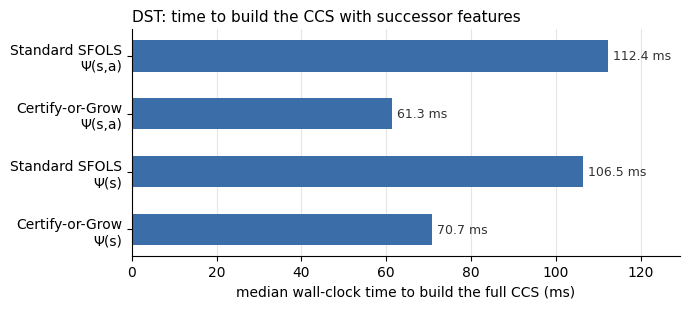

In [13]:
labels = ["Standard SFOLS\nΨ(s,a)", "Certify-or-Grow\nΨ(s,a)", "Standard SFOLS\nΨ(s)", "Certify-or-Grow\nΨ(s)"]
medians = [stats(c)[0] for c in configs]

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(labels[::-1], medians[::-1], color="#3b6ea8", height=0.55)
for bar, v in zip(bars, medians[::-1]):
    ax.text(bar.get_width() + max(medians) * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{v:.1f} ms", va="center", fontsize=9, color="#333")
ax.set_xlabel("median wall-clock time to build the full CCS (ms)")
ax.set_xlim(0, max(medians) * 1.15)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="x", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
ax.set_title("DST: time to build the CCS with successor features", fontsize=11, loc="left")
plt.tight_layout()
plt.show()

## 8. Reading the result

*(Approximate figures from the executed run; wall-clock numbers vary run to run.)*

- **Both methods return the same CCS**: all 10 ground-truth vertices, nothing extra, from the
  same 19 queried weights. The SF tables agree to ~1e-15 at every $(s,a)$, and every CCS
  policy is optimal at every state for the weight it was obtained at.
- **Both CCSs transfer one-shot**: GPI over the full tables and election over state SFs give
  zero regret at every state on all 1001 unseen weights. GPI over the 2-policy basis alone
  has regret on 62 of them - which is why the metapolicies' SFs have to be kept.
- **Speedup**: ~1.5-1.6x end to end, ~2.3-2.5x on the solving itself, 2.7x in linear solves
  (209 vs 77). Certify-or-Grow does 2 exact solves instead of 19; its restricted PI needs ~2
  sweeps per query vs ~10 for full PI from scratch. The end-to-end figure is diluted by OLS's
  own bookkeeping (the $\Delta(w)$ LPs), identical for both and ~35-40% of standard's time.
- **Storing the SFs costs the same for both** (~3 ms for $\Psi(s)$, <1 ms more for
  $\Psi(s,a)$), so "state" vs "full" barely changes the ratio. The speedup comes entirely from
  replacing full-action PI with restricted PI.

**Caveats.**
- DST is the easy case for Certify-or-Grow: the 2 corner policies certify every queried
  weight, so there are no fallback solves. Each fallback costs one standard solve plus the
  failed restricted PI, so the speedup shrinks on domains that need them (Office).
- Exact model everywhere. With Q-learning, learning $\Psi$ *is* the solve, and the
  certificate can no longer be checked exactly - a separate experiment.
- Timings are milliseconds on a 72-state MDP; the linear-solve count is the more portable
  comparison.

# Part 9 - Does it hold with Q-learning?

Parts 1-8 solve every policy exactly. Here the successor features are **learned**: every
per-weight solve is replaced by tabular SF Q-learning (SFQL, the vector TD update of
`RM/sf-fsa-vi/sfols/rl/successor_features/tabular_sf.py`). The OLS loop and `Policy` record are
unchanged, and all methods share one learner, `sfql`, which differs only in its initialization
and the actions it may use:

| arm | per queried weight `w` | init |
|---|---|---|
| **standard SFOLS** | SFQL over the full action set | optimistic, $\Psi\cdot w$ above every return |
| **standard SFOLS + GPI warm start** | SFQL over the full action set | $\Psi(s,a) = \Psi_{j^*}(s,a)$, GPI over the policies learned so far |
| **Certify-or-Grow + warm start** | SFQL restricted (acting *and* bootstrapping) to $B(s)$, the basis policies' own actions | GPI over the basis **and every metapolicy certified so far** (the pool $\mathcal P$) |
| **Certify-or-Grow + warm start, model-free certificate** | same restricted SFQL, then one sampled transition per off-$B(s)$ pair | same as the previous arm |

The second arm is there to separate the two things Certify-or-Grow does - reusing earlier
policies (warm start) and shrinking the action set (restriction) - so the speedup isn't
credited to the restriction alone. The third arm gives Certify-or-Grow the same reuse the
second arm has: GPI over every policy available so far (the basis and the certified
metapolicies). *(A variant warm-started from the basis only was dropped: it reaches the same
metapolicies and was at most 1.2x more expensive.)* It is *not*
$\pi^{\mathrm{hyb}}$, which acts over the full action set and is a query-time improvement, not a
way to compute a CCS element.

**Fourth arm - model-free certificate.** The Certify-or-Grow arms above check the certificate with
the model (exact evaluation of the learned metapolicy plus a one-step lookahead over every
action), which costs no environment steps. The fourth arm removes that in two phases. First it
learns the metapolicy exactly as the third arm does (SFQL restricted to $B(s)$ for acting and
bootstrapping). Then it **completes** the table outside $B(s)$ with one sampled transition per
missing $(s,a)$:
$\hat\Psi(s,a) = \phi(s,a,s') + \gamma\,\hat\Psi(s',\pi_{\mathrm{meta}}(s'))$.
The right-hand side only uses the metapolicy's own, already learned entries, and DST is
deterministic, so one sample is exact (a stochastic domain would average a few). Since
$\Psi^{\pi_{\mathrm{meta}}}(s,a)\cdot w = \phi(s,a)\cdot w + \gamma\,\mathbb E[V_{\mathrm{meta}}(s')]$,
the gap is then read off the completed table, $\max_a \hat\Psi(s,a)\cdot w - \hat\Psi(s,\pi_{\mathrm{meta}}(s))\cdot w$,
with no model. Completion uses the same exploring starts as SFQL (free resets to a uniformly
random non-terminal state) and every completion transition is counted as an environment step.
*(An earlier version of this arm instead explored all actions during learning; it cost ~3.7x more
steps than the pool arm and was replaced.)*

**Design choices** (identical across arms):
- *Cost = environment steps.* Wall-clock time is reported too, but it depends on this Python
  loop. We report both the steps actually run and the **steps to converge** (the step of the
  last update that changed anything); the difference is what it costs to *confirm* convergence.
- *Stopping rule:* stop once **every** allowed $(s,a)$ has been updated since the last update
  that changed any SF component by more than 1e-6. With $\alpha=1$ on a deterministic MDP the
  whole table is then a fixed point, i.e. the exact SFs of the learned policy. No ground truth
  is used. Why not something cheaper - see the note below.
- *Exploring starts:* each episode starts at a uniformly random non-terminal state, so the
  learned SFs cover every state - needed both for the certificate (which checks every state)
  and for GPI at unseen weights.
- *$\alpha = 1$:* DST is deterministic, so one sampled backup is exact; $\varepsilon = 0.1$.
- *The certificate is still exact.* Certify-or-Grow evaluates the **learned** metapolicy with
  the model and checks its full-action Bellman gap. This is a hybrid (learned SFs, model-based
  certificate); a sample-based certificate is a separate question.
- The learned metapolicy's SFs are only learned for $a \in B(s)$; the other entries are marked
  NaN so GPI never picks them (GPI over each policy's own actions keeps the
  $V \ge \max_j V^{\pi_j}$ guarantee).

**Note - the stopping rule has to watch the SFs, not the values.** A first version stopped when
the greedy policy and $\Psi(s,a)\cdot w$ had been stable for a few windows (the usual Q-learning
check). Everything looked right - all 10 CCS points, exact $\psi(s_0)$ - but GPI over standard
SFOLS's learned tables had regret ~99 (the agent loops forever) on 1000 of 1001 unseen weights.
Cause: the corner policy for $w=(0,1)$ starts from the optimistic $\Psi=(25,0)$, and under that
weight the treasure component contributes nothing to $\Psi\cdot w$. So off-greedy entries kept
stale treasure values (off by up to 8), invisible to a value-based check; at any other weight they
look like a treasure worth ~25 and GPI follows them. Watching every SF component helps but isn't
enough, because a rarely taken $(s,a)$ can go the whole quiet window unvisited. Hence the rule
above: a learned SF table is only safe for transfer once every entry has been re-confirmed.

In [14]:
import random

OPTIMISTIC_PSI = np.array([25.0, 0.0])   # Psi.w upper-bounds every return for w in the simplex
Q_ALPHA = 1.0          # deterministic domain: a full step is the exact sampled backup
Q_EPS = 0.1
Q_HORIZON = 100        # episode cap before a restart
Q_CHECK = 200         # steps between convergence checks
Q_TOL = 1e-6          # an update larger than this (any SF component) counts as a change
Q_MAX_STEPS = 500_000

_NEXT_L = NEXT.tolist()
_DONE_L = DONE.tolist()
_NONTERM_IDX = np.flatnonzero(NONTERM).tolist()


def sfql(w, psi_init, allowed, rng, behavior=None):
    # Tabular SF Q-learning (SFQL) at weight w, restricted to allowed[s,a] for both acting and
    # bootstrapping. Episodes start at a uniformly random non-terminal state (exploring starts).
    # Stops once EVERY allowed non-terminal (s,a) has been updated since the last update that
    # changed any SF component by more than Q_TOL: with alpha=1 on a deterministic MDP the whole
    # table is then a fixed point. Steps-to-converge = the step of that last change.
    Psi = psi_init.copy()
    Qw = Psi @ w
    masked_inf = np.where(allowed, 0.0, -np.inf)
    # behavior: actions that may be tried (default: the allowed ones). Greedy choices and bootstrap
    # targets always use `allowed`; with behavior=FULL the extra actions are evaluated off-policy.
    behavior = allowed if behavior is None else behavior
    allowed_l = [np.flatnonzero(behavior[s]).tolist() for s in range(S)]
    tracked = behavior & NONTERM[:, None]
    last_update = np.full((S, N_ACTIONS), -1)
    last_change = 0

    def greedy(s):
        return int((Qw[s] + masked_inf[s]).argmax())

    steps, t_ep, s, done_learning = 0, Q_HORIZON, None, False
    while steps < Q_MAX_STEPS:
        if s is None or t_ep >= Q_HORIZON:
            s, t_ep = rng.choice(_NONTERM_IDX), 0
        a = rng.choice(allowed_l[s]) if rng.random() < Q_EPS else greedy(s)
        ns, done = _NEXT_L[s][a], _DONE_L[s][a]
        target = PHI[s, a] if done else PHI[s, a] + GAMMA * Psi[ns, greedy(ns)]
        delta = Q_ALPHA * (target - Psi[s, a])
        steps += 1
        if np.abs(delta).max() > Q_TOL:
            last_change = steps
        Psi[s, a] += delta
        Qw[s, a] = Psi[s, a] @ w
        last_update[s, a] = steps
        t_ep += 1
        s = None if done else ns
        if steps % Q_CHECK == 0 and last_update[tracked].min() > last_change:
            done_learning = True
            break
    if not done_learning:
        PROF.n["learns that hit the step cap"] += 1
    PROF.n["env steps"] += steps
    PROF.n["env steps to converge"] += last_change
    PROF.log.append(last_change)
    PROF.log_total.append(steps)
    return Psi, steps


def learned_policy(w, Psi, allowed, source, learned=None):
    actions = np.where(allowed, Psi @ w, -np.inf).argmax(axis=1)
    psi_s = Psi[np.arange(S), actions] * NONTERM[:, None]
    # entries that were never learned are marked NaN so GPI can't pick them
    learned = allowed if learned is None else learned
    return Policy(w, actions, psi_s, np.where(learned[..., None], Psi, np.nan), source)


FULL = np.ones((S, N_ACTIONS), dtype=bool)


def gpi_init(w, tables):
    # Psi_init(s,a) = Psi_j*(s,a), j* = argmax_j Psi_j(s,a).w   (GPI over already-learned tables;
    # NaN = entry never learned by that table, never selected)
    T = np.stack(tables)
    j = np.nan_to_num(np.einsum("nsad,d->nsa", T, w), nan=-np.inf).argmax(axis=0)
    return np.take_along_axis(T, j[None, ..., None], axis=0)[0]


def solve_q(w, rng, warm_tables=None):
    # Standard per-weight learner: full action set, optimistic init or GPI warm start
    init = np.tile(OPTIMISTIC_PSI, (S, N_ACTIONS, 1)) if not warm_tables else gpi_init(w, warm_tables)
    init[TERMINAL] = 0.0
    with PROF.section("Q-learning: full action set"):
        Psi, _ = sfql(w, init, FULL, rng)
    PROF.n["full learns"] += 1
    return learned_policy(w, Psi, FULL, "q-full")


class StandardQ:
    def __init__(self, rng, warm=False):
        self.rng, self.warm, self.learned = rng, warm, []

    def __call__(self, w):
        p = solve_q(w, self.rng, [q.psi_sa for q in self.learned] if self.warm else None)
        self.learned.append(p)
        return p


class CertifyOrGrowQ:
    # Certify-or-Grow with learned SFs: the metapolicy is learned by SFQL restricted to the basis
    # policies' own actions B(s), warm-started by GPI over the basis' SFs -- plus, with pool=True,
    # over every metapolicy certified so far (the pool P). The certificate is the EXACT Bellman gap
    # of the learned (restricted-greedy) policy -- it uses the model.
    def __init__(self, rng, pool=False, cert_tol=1e-6):
        self.rng, self.use_pool, self.cert_tol = rng, pool, cert_tol
        self.pool = []
        with PROF.section("basis: initial corner learns"):
            self.basis = [solve_q(np.eye(FEAT_DIM)[i], rng) for i in range(FEAT_DIM)]

    def __call__(self, w):
        allowed = self._allowed()
        sources = self.basis + (self.pool if self.use_pool else [])
        init = np.where(allowed[..., None], gpi_init(w, [p.psi_sa for p in sources]), 0.0)
        with PROF.section("Q-learning: restricted (metapolicy)"):
            Psi, _ = sfql(w, init, allowed, self.rng)
        policy = learned_policy(w, Psi, allowed, "q-meta")
        with PROF.section("certificate (exact model)"):
            V = value(policy.actions, w)
            gap = (q_backup(V, w).max(axis=1) - V)[NONTERM].max()
        return self._certify_or_grow(w, policy, gap)

    def _allowed(self):
        own = np.stack([p.actions for p in self.basis])                 # (k, S)
        allowed = np.zeros((S, N_ACTIONS), dtype=bool)
        allowed[np.arange(S)[None, :].repeat(len(own), 0), own] = True
        return allowed

    def _certify_or_grow(self, w, policy, gap):
        if gap > self.cert_tol:
            PROF.n["fallbacks"] += 1
            p = solve_q(w, self.rng)
            self.basis.append(p)
            return p
        PROF.n["certified"] += 1
        if not any(np.allclose(policy.psi0, q.psi0, atol=1e-6) for q in self.pool):
            self.pool.append(policy)      # one table per distinct psi(s0), like the CCS itself
        return policy


class CertifyOrGrowQModelFree(CertifyOrGrowQ):
    # Fully model-free Certify-or-Grow (with the pool warm start), in two phases:
    #  1. learn the metapolicy exactly as the pool arm does: SFQL restricted to B(s) for both
    #     acting and bootstrapping -- same samples, same table on B(s);
    #  2. complete the table outside B(s) with ONE sampled transition per missing (s,a):
    #         Psi(s,a) = phi(s,a,s') + gamma * Psi(s', pi_meta(s'))
    #     The right-hand side only uses the metapolicy's own (already learned) entries, and DST is
    #     deterministic, so one sample per pair is exact -- no fixed point, nothing to confirm.
    # The Bellman gap is then read off the completed table, no model:
    #     gap(s) = max_a Psi(s,a).w - Psi(s, pi_meta(s)).w
    # Completion uses the same exploring starts as SFQL: an episode starts at a uniformly random
    # non-terminal state (resets cost no environment step, as everywhere in this notebook); it
    # takes one not-yet-sampled action outside B(s), and keeps going from s' while s' still has
    # one, otherwise it resets. Every completion transition is counted as an environment step.
    def __init__(self, rng, cert_tol=1e-6):
        super().__init__(rng, pool=True, cert_tol=cert_tol)

    def __call__(self, w):
        allowed = self._allowed()
        sources = self.basis + self.pool
        init = np.where(allowed[..., None], gpi_init(w, [p.psi_sa for p in sources]), 0.0)
        with PROF.section("Q-learning: restricted (metapolicy)"):
            Psi, _ = sfql(w, init, allowed, self.rng)
        policy_actions = np.where(allowed, Psi @ w, -np.inf).argmax(axis=1)
        with PROF.section("completion outside B(s)"):
            steps = self._complete(Psi, allowed, policy_actions)
        PROF.n["env steps"] += steps
        PROF.n["env steps to converge"] += steps
        PROF.n["completion steps"] += steps
        PROF.log[-1] += steps          # charge the completion to this query's learn
        PROF.log_total[-1] += steps
        policy = learned_policy(w, Psi, allowed, "q-meta-mf", learned=FULL)
        Qw = Psi @ w
        gap = (Qw.max(axis=1) - Qw[np.arange(S), policy.actions])[NONTERM].max()
        return self._certify_or_grow(w, policy, gap)

    def _complete(self, Psi, allowed, actions):
        todo = [[a for a in range(N_ACTIONS) if not allowed[s, a]] if NONTERM[s] else []
                for s in range(S)]
        left = sum(len(t) for t in todo)
        steps, s = 0, None
        while left:
            if s is None or not todo[s]:
                s = self.rng.choice(_NONTERM_IDX)          # exploring start (free reset)
                PROF.n["completion episodes"] += 1
                continue
            a = todo[s].pop(self.rng.randrange(len(todo[s])))
            ns, done = _NEXT_L[s][a], _DONE_L[s][a]        # one environment step
            Psi[s, a] = PHI[s, a] if done else PHI[s, a] + GAMMA * Psi[ns, actions[ns]]
            steps += 1
            left -= 1
            s = None if done else ns
        return steps


def run_q(method, seed):
    global PROF
    PROF = Profile()
    rng = random.Random(seed)
    t0 = time.perf_counter()
    query = {"standard": lambda: StandardQ(rng),
             "standard-warm": lambda: StandardQ(rng, warm=True),
             "certify": lambda: CertifyOrGrowQ(rng),
             "certify-pool": lambda: CertifyOrGrowQ(rng, pool=True),
             "certify-mf": lambda: CertifyOrGrowQModelFree(rng)}[method]()
    ccs, n_queries = ols(query)
    return dict(ccs=ccs, n_queries=n_queries, total=time.perf_counter() - t0, prof=PROF,
                basis=getattr(query, "basis", None))

## 9.1 Build the CCS with learned SFs, 10 seeds per arm

In [15]:
Q_SEEDS = range(10)
Q_ARMS = {"standard": "standard SFOLS", "standard-warm": "standard + GPI warm start",
          "certify-pool": "CoG + warm start",
          "certify-mf": "CoG + warm start, model-free"}
import os
import pickle

# cache of the learned runs: delete the file (or set RECOMPUTE_Q = True) to rerun the experiment
RECOMPUTE_Q = False
Q_CACHE = os.path.join("results", "dst_q_runs.pkl")


def load_or_run(compute):
    if not RECOMPUTE_Q and os.path.exists(Q_CACHE):
        with open(Q_CACHE, "rb") as f:
            runs = pickle.load(f)
        print(f"loaded cached runs from {Q_CACHE}")
        return runs
    runs = compute()
    os.makedirs(os.path.dirname(Q_CACHE), exist_ok=True)
    try:
        with open(Q_CACHE, "wb") as f:
            pickle.dump(runs, f)
        print(f"cached runs to {Q_CACHE}")
    except Exception as e:                                         # never lose a long run to a cache error
        os.remove(Q_CACHE)
        print(f"could not cache runs ({e!r})")
    return runs


q_runs = load_or_run(lambda: {arm: [run_q(arm, seed) for seed in Q_SEEDS] for arm in Q_ARMS})


def ccs_quality(r):
    # judge each CCS policy by its TRUE psi(s0) (exact evaluation of its action map)
    true = np.array([sf_state(p.actions)[S0] for p in r["ccs"]])
    learned = np.array([p.psi0 for p in r["ccs"]])
    found = sum(np.linalg.norm(true - g, axis=1).min() < 1e-6 for g in ground_truth_ccs)
    spurious = sum(np.linalg.norm(ground_truth_ccs - x, axis=1).min() > 1e-6 for x in true)
    # whole learned table vs. the policy's true Psi(s,a) (NaN = never-learned entries, skipped)
    table_err = max(np.nanmax(np.abs(p.psi_sa - sf_backup(sf_state(p.actions)))[NONTERM])
                    for p in r["ccs"])
    return found, spurious, np.abs(true - learned).max(), table_err


print(f"{len(Q_SEEDS)} seeds per arm; env steps are totals for the whole CCS (median over seeds)\n")
print(f"{'arm':26s} {'CCS found':>9s} {'spurious':>8s} {'psi0 err':>8s} {'table err':>9s} {'full learns':>11s} "
      f"{'certified':>9s} {'fallbacks':>9s} {'env steps':>10s} {'to converge':>11s} {'time (s)':>8s}")
for arm, label in Q_ARMS.items():
    rs = q_runs[arm]
    q = np.array([ccs_quality(r) for r in rs])
    med = lambda key: np.median([r["prof"].n[key] for r in rs])
    print(f"{label:26s} {f'{int(q[:, 0].min())}/{len(ground_truth_ccs)}':>9s} {int(q[:, 1].max()):>8d} "
          f"{q[:, 2].max():>8.0e} {q[:, 3].max():>9.0e} {med('full learns'):>11.0f} {med('certified'):>9.0f} "
          f"{med('fallbacks'):>9.0f} {med('env steps'):>10.0f} {med('env steps to converge'):>11.0f} "
          f"{np.median([r['total'] for r in rs]):>8.2f}")
cap_hits = sum(r["prof"].n["learns that hit the step cap"] for rs in q_runs.values() for r in rs)
print(f"\n(worst seed shown for 'CCS found', 'spurious', the two errors; learns that hit the step cap: {cap_hits})")

cached runs to results/dst_q_runs.pkl
10 seeds per arm; env steps are totals for the whole CCS (median over seeds)

arm                        CCS found spurious psi0 err table err full learns certified fallbacks  env steps to converge time (s)
standard SFOLS                 10/10        0    0e+00     0e+00          19         0         0    2061900     1025464    45.90
standard + GPI warm start      10/10        0    0e+00     0e+00          19         0         0    1508100      493845    22.47
CoG + warm start               10/10        0    0e+00     0e+00           2        19         0     406800      151799     7.58


CoG + warm start, model-free     10/10        0    0e+00     0e+00           2        19         0     431192      152404     7.08

(worst seed shown for 'CCS found', 'spurious', the two errors; learns that hit the step cap: 0)


### Speedups

Ratios of medians over seeds. "Env steps" is what each arm actually spends, including
confirming convergence (revisiting every allowed $(s,a)$ after the last change - far more
entries for the full action set). "Steps to converge" counts only up to the last change.

In [16]:
def q_med(arm, key):
    if key == "time":
        return np.median([r["total"] for r in q_runs[arm]])
    return np.median([r["prof"].n[key] for r in q_runs[arm]])

SPEEDUP_PAIRS = [("certify-pool", "standard"), ("certify-pool", "standard-warm"),
                 ("certify-mf", "standard"), ("certify-mf", "standard-warm"), ("certify-mf", "certify-pool")]
print(f"{'speedup of':30s} {'over':28s} {'env steps':>10s} {'steps to converge':>18s} {'wall time':>10s}")
for arm, base in SPEEDUP_PAIRS:
    print(f"{Q_ARMS[arm]:30s} {Q_ARMS[base]:28s} "
          f"{q_med(base, 'env steps') / q_med(arm, 'env steps'):>9.2f}x "
          f"{q_med(base, 'env steps to converge') / q_med(arm, 'env steps to converge'):>17.2f}x "
          f"{q_med(base, 'time') / q_med(arm, 'time'):>9.2f}x")
print("\nfor reference, the exact version (Part 7): "
      f"{runs[('standard', True)][0]['prof'].n['linear solves'] / runs[('certify', True)][0]['prof'].n['linear solves']:.2f}x "
      "in linear solves")

speedup of                     over                          env steps  steps to converge  wall time
CoG + warm start               standard SFOLS                    5.07x              6.76x      6.05x
CoG + warm start               standard + GPI warm start         3.71x              3.25x      2.96x
CoG + warm start, model-free   standard SFOLS                    4.78x              6.73x      6.48x
CoG + warm start, model-free   standard + GPI warm start         3.50x              3.24x      3.17x
CoG + warm start, model-free   CoG + warm start                  0.94x              1.00x      1.07x

for reference, the exact version (Part 7): 2.71x in linear solves


### Where the steps go: cost per OLS query

All four arms query the same 19 weights in the same order (same OLS loop, same exact CCS), so
costs are aligned **by query**. Queries 1-2 are the extremes $e_1, e_2$ - exactly the weights of
Certify-or-Grow's two basis corners. Certify-or-Grow learns those corners before the loop and then
answers queries 1-2 for free, so we count each corner's learning cost at the query with the same
weight: every arm then pays for the extremes at queries 1-2, and totals are unchanged. A 0 means
the starting table was already the exact answer.

In [17]:
def per_query(r, key="log"):
    # Per-query cost aligned with the OLS query order. For Certify-or-Grow the 2 basis-corner
    # learns (logged first) are counted at queries 1-2, whose weights e_1, e_2 they were learned for.
    costs = np.array(getattr(r["prof"], key))
    if r["basis"] is not None:
        basis, costs = costs[:FEAT_DIM], costs[FEAT_DIM:].copy()
        costs[:FEAT_DIM] += basis
    assert len(costs) == r["n_queries"], "a fallback learn would break the alignment"
    return costs


seed0 = {arm: per_query(q_runs[arm][0]) for arm in Q_ARMS}
W = 25
print("steps to converge per OLS query (seed 0; queries 1-2 include Certify-or-Grow's basis corners)\n")
print(f"{'query':>5s} " + " ".join(f"{Q_ARMS[a]:>{W}s}" for a in Q_ARMS))
for i in range(q_runs["standard"][0]["n_queries"]):
    print(f"{i + 1:>5d} " + " ".join(f"{c[i]:>{W}d}" for c in seed0.values()))
print(f"{'total':>5s} " + " ".join(f"{c.sum():>{W}d}" for c in seed0.values()))

steps to converge per OLS query (seed 0; queries 1-2 include Certify-or-Grow's basis corners)

query            standard SFOLS standard + GPI warm start          CoG + warm start CoG + warm start, model-free
    1                     91013                     91013                     91013                     91181
    2                     27759                     36609                     27759                     27927
    3                     31930                     38292                      3384                      3290
    4                     48565                     20539                       683                       637
    5                     25856                     22850                      1033                       785
    6                     75235                     71933                      1786                      1825
    7                     26341                     10056                       865                       730
    8                 

### Figure: cumulative sample cost of building the CCS

Mean over the 10 seeds, shaded band = $\pm 1$ standard deviation. Every arm starts at 0;
Certify-or-Grow's two basis corners are counted at queries 1-2 (the extremes they are learned for).
**(a)** environment steps until the last update that changed an SF entry; **(b)** all
environment steps, including confirming convergence. The figure is also saved as a PDF to
`notes/figures/dst_q_ccs_cost.pdf`.

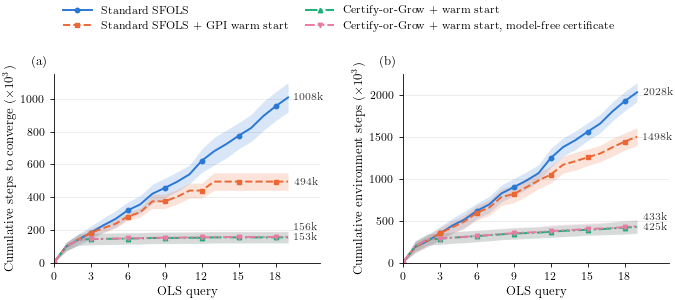

saved ../notes/figures/dst_q_ccs_cost.pdf  (TeX rendering: True)

mean +- std over 10 seeds, whole CCS:
  Standard SFOLS                     to converge   1008.1k +-  90.0k
  Standard SFOLS                     env steps     2028.1k +- 114.3k
  Standard SFOLS + GPI warm start    to converge    494.1k +-  53.6k
  Standard SFOLS + GPI warm start    env steps     1498.4k +- 104.9k
  Certify-or-Grow + warm start       to converge    153.4k +-  35.1k
  Certify-or-Grow + warm start       env steps      425.1k +-  78.3k
  Certify-or-Grow + warm start, model-free certificate to converge    156.3k +-  34.2k
  Certify-or-Grow + warm start, model-free certificate env steps      432.6k +-  78.1k


In [18]:
import os
import shutil

os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"   # MacTeX, if the kernel's PATH lacks it
USE_TEX = shutil.which("latex") is not None

PUB_RC = {
    "text.usetex": USE_TEX,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
}
# categorical palette, fixed order; line style + marker as a second, colour-free encoding
ARM_STYLE = {
    "standard":      dict(color="#2a78d6", ls="-",  marker="o"),
    "standard-warm": dict(color="#eb6834", ls="--", marker="s"),
    "certify-pool":  dict(color="#1baf7a", ls="-.", marker="^"),
    "certify-mf":    dict(color="#e87ba4", ls=(0, (5, 1.5, 1, 1.5, 1, 1.5)), marker="v"),
}
ARM_LABEL = {"standard": "Standard SFOLS", "standard-warm": "Standard SFOLS + GPI warm start",
             "certify-pool": "Certify-or-Grow + warm start",
             "certify-mf": "Certify-or-Grow + warm start, model-free certificate"}


def cumulative(r, key):
    return np.concatenate([[0], np.cumsum(per_query(r, key))])


def label_ends(ax, ends, x, min_gap):
    # value labels at the line ends, nudged apart so they never overlap
    placed = []
    for arm, y in sorted(ends.items(), key=lambda kv: kv[1]):
        y_txt = max(y, placed[-1] + min_gap) if placed else y
        placed.append(y_txt)
        ax.annotate(f"{y:.0f}k", xy=(x, y), xytext=(x + 0.5, y_txt), va="center", ha="left",
                    fontsize=7.5, color="#333333")


panels = [("log", r"Cumulative steps to converge ($\times 10^3$)"),
          ("log_total", r"Cumulative environment steps ($\times 10^3$)")]

with plt.rc_context(PUB_RC):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7))
    for ax, (key, ylabel), tag in zip(axes, panels, "ab"):
        ends = {}
        for arm in Q_ARMS:
            Y = np.stack([cumulative(r, key) for r in q_runs[arm]]) / 1000
            mean, std = Y.mean(axis=0), Y.std(axis=0)
            x = np.arange(len(mean))
            st = ARM_STYLE[arm]
            ax.fill_between(x, mean - std, mean + std, color=st["color"], alpha=0.18, lw=0)
            ax.plot(x, mean, color=st["color"], ls=st["ls"], lw=1.8 if st["ls"] == ":" else 1.4,
                    marker=st["marker"], ms=3.2,
                    markevery=3, label=ARM_LABEL[arm])
            ends[arm] = mean[-1]
        label_ends(ax, ends, x[-1], min_gap=0.06 * max(ends.values()))
        ax.set_xlim(0, x[-1] + 2.6)
        ax.set_ylim(bottom=0)
        ax.set_xticks(np.arange(0, x[-1] + 1, 3))
        ax.set_xlabel("OLS query")
        ax.set_ylabel(ylabel)
        ax.text(-0.02, 1.03, rf"({tag})", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.grid(axis="y", color="#e6e6e6", lw=0.5)
        ax.set_axisbelow(True)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2,
               frameon=False, handlelength=2.6, columnspacing=1.6)
    fig.tight_layout(w_pad=2.0)
    out = os.path.join("..", "notes", "figures", "dst_q_ccs_cost.pdf")
    fig.savefig(out)
    plt.show()

print(f"saved {out}  (TeX rendering: {USE_TEX})")
print(f"\nmean +- std over {len(Q_SEEDS)} seeds, whole CCS:")
for arm in Q_ARMS:
    for key, name in (("log", "to converge"), ("log_total", "env steps")):
        t = np.array([cumulative(r, key)[-1] for r in q_runs[arm]]) / 1000
        print(f"  {ARM_LABEL[arm]:34s} {name:12s} {t.mean():7.1f}k +- {t.std():5.1f}k")

# raw per-seed cumulative curves, read by plot_ccs_cost_combined.py (DST + Office figure)
data_dir = os.path.join("..", "notes", "figures", "data")
os.makedirs(data_dir, exist_ok=True)
np.savez(os.path.join(data_dir, "dst_q_ccs_cost.npz"),
         **{f"{arm}__{key}": np.stack([cumulative(r, key) for r in q_runs[arm]]) for arm in Q_ARMS for key, _ in panels})


## 9.2 One-shot transfer with the *learned* SFs

Same 1001 unseen weights as Part 6, now using each arm's learned tables (seed 0). The regret of
the resulting policy is still measured exactly.

In [19]:
def gpi_actions_learned(policies, w):
    # GPI over learned tables; NaN (never-learned) entries can't be selected
    Q = np.einsum("nsad,d->nsa", np.stack([p.psi_sa for p in policies]), w)
    return np.nan_to_num(Q, nan=-np.inf).max(axis=0).argmax(axis=1)


V_star_test = [policy_iteration(w)[1] for w in test_weights]

q_transfer = {}
for arm, label in Q_ARMS.items():
    r = q_runs[arm][0]
    q_transfer[f"{label} + GPI"] = lambda w, c=r["ccs"]: gpi_actions_learned(c, w)
    q_transfer[f"{label} + election"] = lambda w, c=r["ccs"]: election_actions(c, w)
q_transfer["basis only (Certify-or-Grow) + GPI"] = \
    lambda w, c=q_runs["certify-pool"][0]["basis"]: gpi_actions_learned(c, w)

print(f"{len(test_weights)} unseen weights, exact regret of the policy built from learned SFs\n")
print(f"{'':42s} {'weights w/ regret at s0':>24s} {'max regret at s0':>17s} {'max regret, any s':>18s}")
for k, f in q_transfer.items():
    gaps = [V_star - value(f(w), w) for w, V_star in zip(test_weights, V_star_test)]
    r = np.array([(g[S0], g[NONTERM].max()) for g in gaps])
    print(f"{k:42s} {int((r[:, 0] > 1e-6).sum()):>24d} {r[:, 0].max():>17.5f} {r[:, 1].max():>18.5f}")

1001 unseen weights, exact regret of the policy built from learned SFs

                                            weights w/ regret at s0  max regret at s0  max regret, any s


standard SFOLS + GPI                                              0           0.00000            0.00000


standard SFOLS + election                                         0           0.00000            0.00000


standard + GPI warm start + GPI                                   0           0.00000            0.00000


standard + GPI warm start + election                              0           0.00000            0.00000


CoG + warm start + GPI                                            0           0.00000            0.00000


CoG + warm start + election                                       0           0.00000            0.00000


CoG + warm start, model-free + GPI                                0           0.00000            0.00000


CoG + warm start, model-free + election                           0           0.00000            0.00000


basis only (Certify-or-Grow) + GPI                               62           0.31052            0.92553


## 9.3 Reading the Q-learning result

*(Figures from the executed run: medians over 10 seeds unless stated.)*

**The results carry over to learned SFs.**
- All four arms recover all 10 ground-truth CCS points with nothing spurious, on every seed. The
  learned $\psi(s_0)$ **and the whole learned SF tables** match the true SFs of the learned
  policies exactly (error 0). With $\alpha=1$ on a deterministic domain and the full-coverage
  stopping rule, that is expected.
- One-shot transfer works from the learned SFs: GPI and election give zero regret at every state
  on all 1001 unseen weights, for all four CCSs. GPI over the 2-policy basis alone still has
  regret on 62 weights - the metapolicies' SFs have to be kept here too.

**The speedup is larger than in the exact version.**

| speedup of | over | env steps | steps to converge |
|---|---|---|---|
| Certify-or-Grow | standard SFOLS | ~4.5x | ~5.6x |
| Certify-or-Grow | standard + GPI warm start | ~3.3x | ~2.7x |
| Certify-or-Grow + pool | standard SFOLS | ~5.1x | ~6.8x |
| Certify-or-Grow + pool | standard + GPI warm start | ~3.7x | ~3.3x |
| *(exact version, Part 7)* | *standard, in linear solves* | *2.7x* | |

- Per OLS query from query 3 on (seed 0, median), the metapolicy converges in about 3.4k steps,
  against about 44k for standard SFOLS and 10k for the warm-started baseline; with the pool warm
  start, most later queries need 0.
- Across seeds the ordering is never in doubt: whole-CCS steps to converge are
  $1008\pm90$k (standard), $494\pm54$k (warm start), $187\pm33$k (Certify-or-Grow) and
  $153\pm35$k (+ pool), mean $\pm$ std over 10 seeds.
- The warm-start arm splits the gain in two: reusing earlier policies alone halves the steps to
  converge (about 1.01M to 0.49M), and restricting to $B(s)$ gives a further ~2.7-3.3x. Restriction
  helps because each state has 1-2 allowed actions instead of 4, so there are fewer entries to
  learn *and* to confirm.

**The pool warm start (fourth arm).**
- It does what it was meant to: most confirmation queries (corner weights whose optimum is
  already in the CCS; learns 11, 14 and 16-21 in seed 0) start from the exact answer and need 0
  steps to converge, as they do for the warm-started baseline. Steps to converge drop ~1.2x (median about 183k to 152k).
- Total env steps improve less (~1.1x). Even when the starting table is already exact, the
  stopping rule still has to revisit every allowed $(s,a)$ once to *confirm* nothing changes, and
  that confirmation cost is now most of each query. The two basis corners (about 91k + 28k steps
  to converge) are also ~75-80% of this arm's steps to converge, and the pool can't help with them.
- Not every query gets cheaper (learn 15: 5.5k vs 3.9k). A non-optimistic start can slow down the
  queries that do need learning, the same effect seen in the warm-started baseline.
- Since the certificate already uses the model, a cheaper option would be to certify the starting
  table's greedy policy *before* learning and skip the query when it passes. Its SFs would still
  need checking, so this is left as an idea, not tried.

**Without a model (fifth arm).** Learning the metapolicy restricted to $B(s)$ and then completing
the table with one sampled transition per off-$B(s)$ pair keeps everything correct - same CCS,
exact full SF tables, same 19/19 certifications, zero-regret transfer - and costs almost nothing
extra: $0.43 \pm 0.08$M environment steps, against $0.43 \pm 0.08$M for the model-based pool arm
(median ratio 0.94x env steps, 1.00x steps to converge). The completion itself is about 3.2k
transitions over the whole CCS. The model-free arm is therefore **4.8x** cheaper than standard
SFOLS and **3.5x** cheaper than the warm-started baseline in env steps. **On DST, the certificate
no longer needs a model to keep Certify-or-Grow's sample advantage.** The completion relies on
the same free exploring-start resets as every other arm (about 4.8k resets per run).

**Caveats.**
- *Model-free certificate:* exact here because DST is deterministic (one sample per pair). A
  stochastic domain needs several samples per off-$B(s)$ pair, and an estimated gap can produce
  false certificates or false fallbacks.
- The conditions are favourable to tabular learning: exploring starts, $\alpha=1$ on a
  deterministic MDP, and a stopping rule that needs to know every $(s,a)$ has been revisited.
  With stochastic transitions or function approximation, none of these carry over directly.
- DST still needs no fallbacks. On a domain that does (Office), each fallback costs a full
  from-scratch learn.